# Detecção de amastigotas fora do macrófago — experimento 5 (realce de imagem + YOLO11-medium)

- Autor: Clésio Gonçalves
- Os experimentos 1-4 (YOLO11n, YOLO11n+P2, YOLO26-medium, YOLO26-large) convergiram todos para o mesmo patamar de mAP50 (≈ 0.39-0.44), independente do tamanho do modelo. Isso indica que o limitador **não é capacidade do modelo**, e sim algo relacionado aos dados/generalização entre lâminas.
- Este experimento ataca essa hipótese por outro ângulo, com 4 mudanças:
  1. **Pré-processamento de imagem para realçar as leishmanias** — em vez de simplesmente trocar para HSV "no escuro", foi feita uma análise quantitativa (abaixo) comparando o poder de separação leishmania-vs-fundo de 9 canais de cor (RGB, HSV, Lab). O resultado mostrou que o **matiz (H)** é o canal *menos* discriminativo (a coloração é parecida — mesmo corante), e quem realmente separa é **intensidade/luminosidade** (R, L, V — leishmanias são mais escuras que o fundo). Com base nisso, o realce escolhido foi **CLAHE no canal L do espaço Lab** (aumenta contraste local de intensidade, preservando a cor original), não uma simples conversão para HSV.
  2. **Aumento de dados mais agressivo**: jitter de cor (HSV) maior (para dar invariância a variações de coloração entre lâminas), rotação e flip vertical habilitados (não há orientação canônica em uma lâmina de microscopia).
  3. **Taxa de aprendizado inicial menor**: `lr0=0.0005` com otimizador `AdamW` explícito (nos experimentos anteriores o `optimizer=auto` escolhia `lr0≈0.002`).
  4. **Modelo YOLO11-medium** (`yolo11m.pt`, ~20M parâmetros) com `imgsz=512`, usando o recorte original sem upscaling (diferente dos experimentos 2-4, que usavam 640).
- Mesmos recortes-base, mesmas 6 lâminas e mesma divisão de folds dos experimentos anteriores, para comparação direta.

## Resultado

**mAP50 médio: 0.4345 ± 0.1175** — o 2º melhor da série (atrás apenas do Exp.1, 0.4391, dentro da margem de desvio padrão — ou seja, estatisticamente equivalente). Mais importante: este experimento obteve o **melhor recall de toda a série (0.5170)**, sugerindo que o aumento de dados + invariância de cor ajudou o modelo a generalizar um pouco melhor para variações entre lâminas (menos falsos negativos). No diagnóstico por lâmina, `leish_1` e `leish_9` tiveram o melhor resultado já visto na série, mas `leish_3` permanece o pior caso (poucas instâncias de leishmania nessa lâmina no dataset original, 10 no total — provável limitação de dados, não de método).

**Conclusão geral da série de 5 experimentos**: nenhuma das intervenções (modelo maior, cabeça P2, realce de imagem, aumento de dados, lr menor) produziu uma melhora grande e inequívoca — todas ficam dentro da margem de variação entre folds (mAP50 ≈ 0.39-0.44). O fator limitante parece ser estrutural: poucas lâminas (8), com tamanhos de amostra muito desiguais entre elas (de 10 a 4725 instâncias de leishmania), tornando a validação cruzada por lâmina ruidosa.

## Utilização da GPU

In [1]:
!nvidia-smi

Tue Jun 23 18:28:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0 Off |                  N/A |
|  0%   33C    P8             17W /  300W |      15MiB /  16303MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from pathlib import Path
from PIL import Image

import torch
from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''

In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V

Author: Clésio Gonçalves

PIL        : 12.0.0
cv2        : 4.13.0
matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
torch      : 2.12.1
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")

## Parâmetros do experimento

In [7]:
# Diretório com os recortes (512x512) ORIGINAIS de macrófagos infectados — gerados em pre_processamento_dataset_recortes.ipynb
diretorio_recortes_original = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados")

# Diretório com os recortes após o realce de contraste (CLAHE no canal L do Lab) — gerado neste notebook
diretorio_recortes_realce = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados_realce")

extensao = '.png'

# Tamanho de treino/inferência = tamanho original do recorte, sem upscaling (diferente dos experimentos 2-4)
tamanho_imagem = 512

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes_original, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Diretórios de trabalho (dataset YOLO próprio deste experimento, pois as imagens são diferentes - realçadas)
diretorio_yolo_folds = os.path.join(diretorio_raiz, "yolo_folds_leishmania_realce")
diretorio_runs = os.path.join(diretorio_raiz, "runs_leishmania_kfold_yolo11m_realce")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Pesos pré-treinados do YOLO11-medium
caminho_pesos_pretreinados = 'yolo11m.pt'

# Hiperparâmetros de treinamento: lr0 menor + otimizador explícito, aumento de dados mais agressivo
parametros_treino = dict(
    epochs=150,
    patience=40,
    imgsz=tamanho_imagem,
    batch=16,
    device=0,
    seed=42,
    workers=8,
    cos_lr=True,
    single_cls=True,
    verbose=False,
    # taxa de aprendizado inicial menor (auto/AdamW escolhia ~0.002 nos experimentos anteriores)
    optimizer='AdamW',
    lr0=0.0005,
    lrf=0.01,
    # aumento de dados mais agressivo: jitter de cor maior (invariância a coloração entre lâminas),
    # rotação e flip vertical habilitados (sem orientação canônica em microscopia)
    hsv_h=0.03,
    hsv_s=0.9,
    hsv_v=0.6,
    degrees=15.0,
    flipud=0.5,
    mixup=0.1,
)

Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Análise exploratória: qual canal de cor separa melhor leishmania do fundo?

Para escolher o realce de forma objetiva (em vez de "tentar HSV no escuro"), compara-se a distribuição de pixels **dentro** das caixas de `leishmania` com a distribuição de pixels de **fundo** (fora de qualquer anotação), em 9 canais: RGB, HSV e Lab. A métrica usada é o **d de Cohen** (diferença de médias normalizada pelo desvio padrão combinado) — quanto maior o valor absoluto, melhor o canal separa as duas classes.

In [8]:
# Amostra algumas lâminas/imagens e extrai pixels dentro das caixas de leishmania vs. fundo, em vários canais de cor
def analisa_separabilidade_canais(diretorio_recortes, laminas, indice_leishmania, n_por_lamina=15, seed=42):
    rng = np.random.default_rng(seed)
    amostras_dentro, amostras_fora = [], []

    for lamina in laminas:
        pasta = os.path.join(diretorio_recortes, lamina)
        arquivos = sorted(f for f in os.listdir(pasta) if f.endswith('.png'))
        escolhidos = rng.choice(arquivos, size=min(n_por_lamina, len(arquivos)), replace=False)

        for arquivo in escolhidos:
            nome_base = os.path.splitext(arquivo)[0]
            txt_path = os.path.join(pasta, f"{nome_base}.txt")
            if not os.path.isfile(txt_path):
                continue
            img_bgr = cv2.imread(os.path.join(pasta, arquivo))
            if img_bgr is None:
                continue
            h, w = img_bgr.shape[:2]

            mascara_leish = np.zeros((h, w), dtype=np.uint8)
            mascara_qualquer = np.zeros((h, w), dtype=np.uint8)
            with open(txt_path) as f:
                for linha in f:
                    linha = linha.strip()
                    if not linha:
                        continue
                    partes = linha.split()
                    cls = int(partes[0])
                    xc, yc, bw, bh = map(float, partes[1:])
                    x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
                    x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
                    x1, y1 = max(0, x1), max(0, y1)
                    x2, y2 = min(w, x2), min(h, y2)
                    mascara_qualquer[y1:y2, x1:x2] = 1
                    if cls == indice_leishmania:
                        mascara_leish[y1:y2, x1:x2] = 1

            if mascara_leish.sum() == 0:
                continue

            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
            img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

            idx_dentro = mascara_leish.astype(bool)
            idx_fora = (mascara_qualquer == 0)

            canais = {
                'R': img_rgb[:, :, 0], 'G': img_rgb[:, :, 1], 'B': img_rgb[:, :, 2],
                'H': img_hsv[:, :, 0], 'S': img_hsv[:, :, 1], 'V': img_hsv[:, :, 2],
                'L': img_lab[:, :, 0], 'a': img_lab[:, :, 1], 'b': img_lab[:, :, 2],
            }
            amostras_dentro.append({k: v[idx_dentro].astype(np.float64) for k, v in canais.items()})
            amostras_fora.append({k: v[idx_fora].astype(np.float64) for k, v in canais.items()})

    linhas = []
    for canal in ['R', 'G', 'B', 'H', 'S', 'V', 'L', 'a', 'b']:
        dentro = np.concatenate([d[canal] for d in amostras_dentro])
        fora = np.concatenate([d[canal] for d in amostras_fora])
        media_d, std_d = dentro.mean(), dentro.std()
        media_f, std_f = fora.mean(), fora.std()
        std_pool = np.sqrt((std_d ** 2 + std_f ** 2) / 2)
        cohen_d = (media_d - media_f) / std_pool if std_pool > 0 else 0
        linhas.append({'canal': canal, 'media_leishmania': media_d, 'media_fundo': media_f, 'cohen_d': cohen_d})

    return pd.DataFrame(linhas).sort_values('cohen_d', key=abs, ascending=False).reset_index(drop=True)


laminas_analise = ['leish_5', 'leish_7', 'leish_9', 'leish_1', 'leish_8']
df_separabilidade = analisa_separabilidade_canais(diretorio_recortes_original, laminas_analise, indice_classe_interesse)
df_separabilidade.round(3)

,canal,media_leishmania,media_fundo,cohen_d
0,R,139.525,151.421,-0.542
1,L,108.025,121.284,-0.525
2,V,145.896,154.556,-0.450
3,G,76.732,90.241,-0.397
4,b,107.821,112.099,-0.360
5,B,133.799,140.072,-0.305
6,a,163.027,159.917,0.244
7,S,121.687,111.163,0.216
8,H,152.093,153.868,-0.099


**Conclusão da análise**: o canal de matiz (`H`, HSV) é o *menos* discriminativo (|d|≈0.1) — leishmania e fundo têm a mesma tonalidade, pois é o mesmo corante. Os canais de **intensidade/luminosidade** (`R`, `L`, `V`) são os mais discriminativos (|d|≈0.45-0.54): as leishmanias são mais escuras que o fundo. Por isso, o realce escolhido é **CLAHE no canal L (Lab)** — aumenta o contraste local de intensidade exatamente onde há mais sinal, sem distorcer a cor (canais `a`/`b` preservados).

## Pré-processamento: aplica CLAHE no canal L (Lab) em todos os recortes

In [9]:
# Aplica CLAHE no canal L (Lab) de uma imagem, preservando os canais de cor (a, b)
def realca_imagem(img_bgr, clip_limit=3.0, tile_grid_size=(16, 16)):
    img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(img_lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    L_eq = clahe.apply(L)
    img_lab_eq = cv2.merge([L_eq, a, b])
    return cv2.cvtColor(img_lab_eq, cv2.COLOR_LAB2BGR)


if os.path.isdir(diretorio_recortes_realce):
    print("Os recortes realçados já foram gerados. Geração ignorada.")
else:
    os.makedirs(diretorio_recortes_realce, exist_ok=True)
    total = 0

    for lamina in sorted(os.listdir(diretorio_recortes_original)):
        pasta_origem = os.path.join(diretorio_recortes_original, lamina)
        if not os.path.isdir(pasta_origem):
            continue

        pasta_destino = os.path.join(diretorio_recortes_realce, lamina)
        os.makedirs(pasta_destino, exist_ok=True)

        for arquivo in sorted(os.listdir(pasta_origem)):
            if arquivo.endswith(extensao):
                img_bgr = cv2.imread(os.path.join(pasta_origem, arquivo))
                img_realcada = realca_imagem(img_bgr)
                cv2.imwrite(os.path.join(pasta_destino, arquivo), img_realcada)
                total += 1
            elif arquivo.endswith('.txt'):
                shutil.copy(os.path.join(pasta_origem, arquivo), os.path.join(pasta_destino, arquivo))

    shutil.copy(os.path.join(diretorio_recortes_original, 'obj.names'), diretorio_recortes_realce)
    print(f"{total} imagens realçadas e salvas em '{diretorio_recortes_realce}'.")

1568 imagens realçadas e salvas em '/mnt/arquivos/Doutorado/dataset_recortes_macrofagos_infectados_realce'.


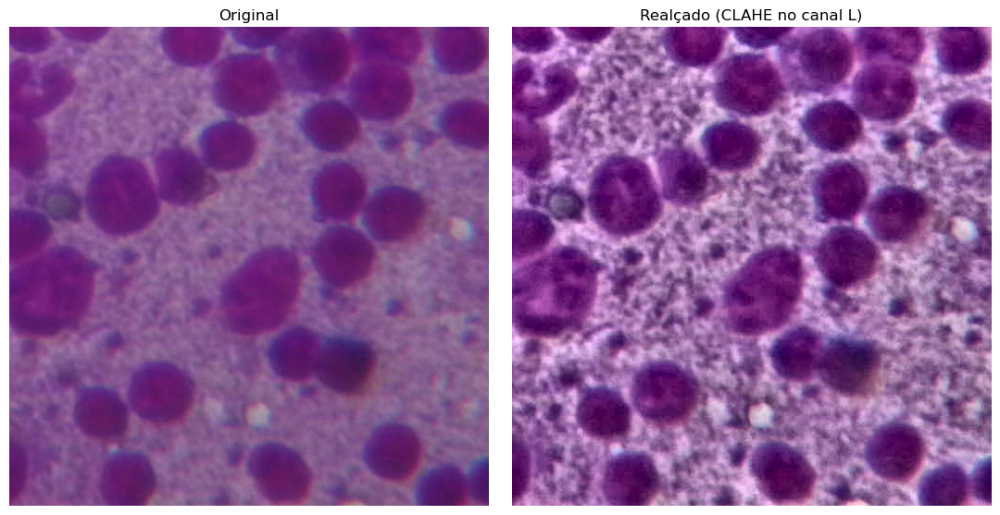

In [10]:
%matplotlib inline
lamina_exemplo, arquivo_exemplo = 'leish_7', sorted(os.listdir(os.path.join(diretorio_recortes_original, 'leish_7')))[0]
img_original = cv2.imread(os.path.join(diretorio_recortes_original, lamina_exemplo, arquivo_exemplo))
img_realcada = cv2.imread(os.path.join(diretorio_recortes_realce, lamina_exemplo, arquivo_exemplo))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original')
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(img_realcada, cv2.COLOR_BGR2RGB))
axes[1].set_title('Realçado (CLAHE no canal L)')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## Definição dos 6 folds (idêntica aos experimentos anteriores, para comparação direta)

In [11]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')

,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold (a partir dos recortes realçados)

In [12]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem (já realçada) e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes_realce, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")

Fold 1: treino=1064 | validação=126 | teste=378
Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449
Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376
Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

In [13]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")

6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Treinamento dos 6 folds (YOLO11-medium, imagens realçadas)

Treinamento local na GPU a partir do checkpoint pré-treinado `yolo11m.pt`. Caso o `best.pt` de um fold já exista, o treinamento desse fold é pulado (idempotente).

In [14]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    if os.path.isfile(caminho_best):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO(caminho_pesos_pretreinados)
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **parametros_treino,
        )
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")
        del modelo
        torch.cuda.empty_cache()

    caminhos_best[n] = caminho_best

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/yolo_folds_leishmania_realce/fold_1/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.03, hsv_s=0.9, hsv_v=0.6, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fold_1, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=40, perspective=0.0, plots=True, pose=12.0, pre

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1      1856  ultralytics.nn.modules.conv.Conv             [3, 64, 3, 2]                 


... (22,216 outputs left out)

                   all         96        831      0.626      0.418      0.467      0.226


Speed: 0.0ms preprocess, 1.6ms inference, 0.0ms loss, 0.3ms postprocess per image


Results saved to /mnt/arquivos/Doutorado/runs_leishmania_kfold_yolo11m_realce/fold_6


Fold 6: treinamento concluído. Pesos em '/mnt/arquivos/Doutorado/runs_leishmania_kfold_yolo11m_realce/fold_6/weights/best.pt'.


## Avaliação no conjunto de teste — agregada por fold

In [15]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11m summary (fused): 126 layers, 20,030,803 parameters, 0 gradients, 67.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 7089.8±602.6 MB/s, size: 453.1 KB)



val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania_realce/fold_1/labels/test... 233 images, 19 backgrounds, 0 corrupt: 61% ━━━━━━━───── 233/378 692.1it/s 0.1s<0.2s


val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania_realce/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 2.0Kit/s 0.2s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania_realce/fold_1/labels/test.cache


... (122 outputs left out)


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 17.2it/s 1.7s

                   all        480       1634      0.356      0.468       0.34      0.136


Speed: 0.2ms preprocess, 2.7ms inference, 0.0ms loss, 0.2ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.524722,0.582049,0.521954,0.180547
2,"leish_2, leish_7",0.539382,0.575690,0.539035,0.209859
3,"leish_1, leish_8",0.358996,0.422114,0.315617,0.128993
4,"leish_4, leish_9",0.359993,0.496266,0.329018,0.133294
5,"leish_1, leish_7",0.609948,0.558413,0.561868,0.212897
6,"leish_2, leish_8",0.355560,0.467564,0.339690,0.136269


In [16]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)

,média,desvio_padrão
precisao,0.4581,0.1132
recall,0.5170,0.0652
mAP50,0.4345,0.1175
mAP50-95,0.1670,0.0391


## Comparação com os experimentos anteriores

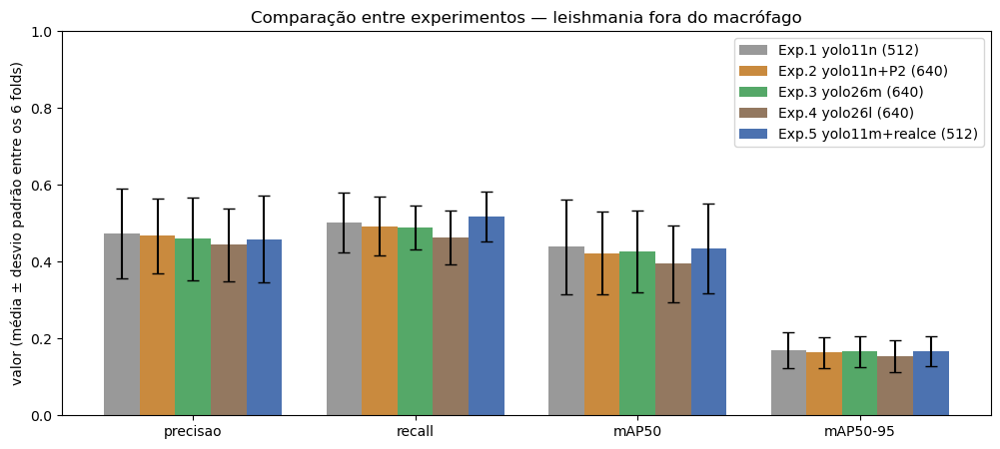

In [17]:
%matplotlib inline
# Médias e desvios padrão dos experimentos anteriores, copiados aqui apenas para referência visual (mesmos 6 folds)
resumo_experimentos_anteriores = {
    'Exp.1 yolo11n (512)': pd.Series({'precisao': 0.4735, 'recall': 0.5012, 'mAP50': 0.4391, 'mAP50-95': 0.1695}),
    'Exp.2 yolo11n+P2 (640)': pd.Series({'precisao': 0.4672, 'recall': 0.4922, 'mAP50': 0.4226, 'mAP50-95': 0.1640}),
    'Exp.3 yolo26m (640)': pd.Series({'precisao': 0.4595, 'recall': 0.4894, 'mAP50': 0.4272, 'mAP50-95': 0.1659}),
    'Exp.4 yolo26l (640)': pd.Series({'precisao': 0.4442, 'recall': 0.4632, 'mAP50': 0.3943, 'mAP50-95': 0.1538}),
}
desvios_experimentos_anteriores = {
    'Exp.1 yolo11n (512)': pd.Series({'precisao': 0.1164, 'recall': 0.0780, 'mAP50': 0.1229, 'mAP50-95': 0.0457}),
    'Exp.2 yolo11n+P2 (640)': pd.Series({'precisao': 0.0981, 'recall': 0.0763, 'mAP50': 0.1083, 'mAP50-95': 0.0405}),
    'Exp.3 yolo26m (640)': pd.Series({'precisao': 0.1079, 'recall': 0.0567, 'mAP50': 0.1068, 'mAP50-95': 0.0396}),
    'Exp.4 yolo26l (640)': pd.Series({'precisao': 0.0946, 'recall': 0.0705, 'mAP50': 0.1000, 'mAP50-95': 0.0417}),
}

metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']
nomes_exp = list(resumo_experimentos_anteriores.keys()) + ['Exp.5 yolo11m+realce (512)']
medias_exp = [resumo_experimentos_anteriores[n][metricas_plot] for n in resumo_experimentos_anteriores] + [resumo_metricas.loc[metricas_plot, 'média']]
desvios_exp = [desvios_experimentos_anteriores[n][metricas_plot] for n in desvios_experimentos_anteriores] + [resumo_metricas.loc[metricas_plot, 'desvio_padrão']]

x = np.arange(len(metricas_plot))
n_exp = len(nomes_exp)
largura = 0.8 / n_exp
cores = ['#999999', '#c98a3e', '#55a868', '#937860', '#4C72B0']

fig, ax = plt.subplots(figsize=(12, 5))
for i, (nome, media, desvio) in enumerate(zip(nomes_exp, medias_exp, desvios_exp)):
    deslocamento = (i - (n_exp - 1) / 2) * largura
    ax.bar(x + deslocamento, media, largura, yerr=desvio, capsize=4, label=nome, color=cores[i % len(cores)])

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1)
ax.set_ylabel('valor (média ± desvio padrão entre os 6 folds)')
ax.set_title('Comparação entre experimentos — leishmania fora do macrófago')
ax.legend()
plt.show()

## Diagnóstico por lâmina (conjunto de teste)

In [18]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11m summary (fused): 126 layers, 20,030,803 parameters, 0 gradients, 67.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 7213.9±442.1 MB/s, size: 459.4 KB)



val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania_realce/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 1.7Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania_realce/fold_1/labels/test_lamina/leish_3.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 2.6it/s 0.1s<0.4s

... (169 outputs left out)


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 18.1it/s 1.3s

                   all        353        992      0.378      0.439      0.336      0.139


Speed: 0.2ms preprocess, 2.7ms inference, 0.0ms loss, 0.2ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.624416,0.390122,0.421193,0.184638
1,leish_1,5,0.599224,0.439230,0.453631,0.195373
2,leish_2,2,0.307755,0.447040,0.280860,0.110713
3,leish_2,6,0.371256,0.495327,0.352954,0.135479
4,leish_3,1,0.125657,0.400000,0.109241,0.045658
5,leish_4,4,0.210741,0.340909,0.137255,0.060640
6,leish_5,1,0.532891,0.583280,0.529100,0.183014
7,leish_7,2,0.619412,0.619799,0.630295,0.245383
8,leish_7,5,0.627513,0.613207,0.613721,0.227503
9,leish_8,3,0.369586,0.462702,0.362634,0.144208


In [19]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)

precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.6118  0.0178     2  0.4147  0.0347     2  0.4374  0.0229     2   
leish_2   0.3395  0.0449     2  0.4712  0.0341     2  0.3169  0.0510     2   
leish_3   0.1257     NaN     1  0.4000     NaN     1  0.1092     NaN     1   
leish_4   0.2107     NaN     1  0.3409     NaN     1  0.1373     NaN     1   
leish_5   0.5329     NaN     1  0.5833     NaN     1  0.5291     NaN     1   
leish_7   0.6235  0.0057     2  0.6165  0.0047     2  0.6220  0.0117     2   
leish_8   0.3739  0.0061     2  0.4506  0.0171     2  0.3494  0.0188     2   
leish_9   0.4806     NaN     1  0.5536     NaN     1  0.4853     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.1900  0.0076     2  
leish_2   0.1231  0.0175     2  
leish_3   0.0457     NaN     1  
leish_4   0.0606     NaN     1  
leish_5   0.1830     NaN     1  
leish_7   0.2364  0.0126     2  
leish_8   0.1418  0.0034     2  
leish_9   0.1945     NaN     1

## Comparação visual: anotação do especialista vs. detecção da YOLO

Em cada imagem: caixas **amarelas** = anotação original do especialista (classe `leishmania`, remapeada); caixas **vermelhas** = detecções do modelo (com confiança). Amostras da lâmina com melhor e da lâmina com pior mAP50 no diagnóstico acima.

In [20]:
# Lê as caixas (em pixels) de um .txt YOLO (classe única já remapeada)
def le_boxes_pixel(txt_path, largura, altura):
    boxes = []
    if os.path.isfile(txt_path):
        with open(txt_path) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                _, xc, yc, w, h = map(float, linha.split())
                boxes.append((xc * largura, yc * altura, w * largura, h * altura))
    return boxes


# Desenha, sobre o mesmo eixo, as caixas do especialista (amarelo) e as detecções do modelo (vermelho)
def desenha_comparacao(eixo, caminho_imagem, caminho_label, modelo, conf=0.25):
    img = Image.open(caminho_imagem)
    largura, altura = img.size
    eixo.imshow(img)

    gt_boxes = le_boxes_pixel(caminho_label, largura, altura)
    for xc, yc, w, h in gt_boxes:
        eixo.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, linewidth=1.5, edgecolor='yellow', facecolor='none'))

    resultado = modelo.predict(caminho_imagem, conf=conf, imgsz=tamanho_imagem, verbose=False)[0]
    for caixa in resultado.boxes:
        x1, y1, x2, y2 = caixa.xyxy[0].tolist()
        confianca = float(caixa.conf[0])
        eixo.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none'))
        eixo.text(x1, max(y1 - 4, 0), f"{confianca:.2f}", color='red', fontsize=7, va='bottom')

    eixo.set_title(f"{os.path.basename(caminho_imagem)}\nespecialista={len(gt_boxes)} | YOLO={len(resultado.boxes)}", fontsize=8)
    eixo.axis('off')


def fold_para_lamina(lamina):
    for fold in folds:
        if lamina in fold['teste']:
            return fold['fold']

Melhor lâmina (mAP50): leish_7 | Pior lâmina (mAP50): leish_3


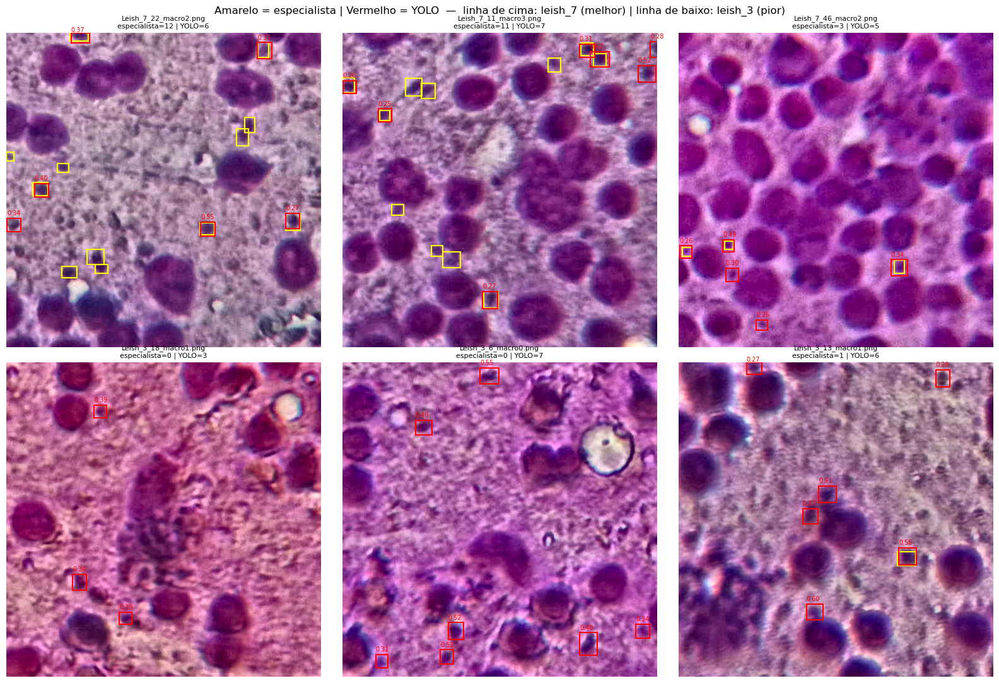

In [21]:
%matplotlib inline
melhor_lamina = resumo_lamina[('mAP50', 'mean')].idxmax()
pior_lamina = resumo_lamina[('mAP50', 'mean')].idxmin()
print(f"Melhor lâmina (mAP50): {melhor_lamina} | Pior lâmina (mAP50): {pior_lamina}")

cache_modelos = {}
def obter_modelo(n_fold):
    if n_fold not in cache_modelos:
        cache_modelos[n_fold] = YOLO(caminhos_best[n_fold])
    return cache_modelos[n_fold]

amostras_comparacao = []
random.seed(42)
for lamina in [melhor_lamina, pior_lamina]:
    n_fold = fold_para_lamina(lamina)
    pasta_img = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'images', 'test_lamina', lamina)
    pasta_lbl = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'labels', 'test_lamina', lamina)
    imagens = sorted(f for f in os.listdir(pasta_img) if f.endswith(extensao))
    escolhidas = random.sample(imagens, min(3, len(imagens)))
    for img_nome in escolhidas:
        amostras_comparacao.append((n_fold, lamina, pasta_img, pasta_lbl, img_nome))

fig, eixos = plt.subplots(2, 3, figsize=(16, 11))
for eixo, (n_fold, lamina, pasta_img, pasta_lbl, img_nome) in zip(eixos.ravel(), amostras_comparacao):
    modelo = obter_modelo(n_fold)
    nome_base = os.path.splitext(img_nome)[0]
    desenha_comparacao(eixo, os.path.join(pasta_img, img_nome), os.path.join(pasta_lbl, f"{nome_base}.txt"), modelo)

fig.suptitle(f"Amarelo = especialista | Vermelho = YOLO  —  linha de cima: {melhor_lamina} (melhor) | linha de baixo: {pior_lamina} (pior)")
plt.tight_layout()
plt.show()